## Listes de 9 questions

MARIUS : Quand et comment les clients commandent-ils généralement ?  

MARIUS : Quels produits faut-il mettre en avant le samedi ?  

MARIUS : Quels autres produits les clients commandent-ils fréquemment avec du chocolat ?  

ANTOINE : Quels sont les principaux profils de clients : acheteurs nocturnes, acheteurs occasionnels ou accros au  panier ?

ANTOINE : Quel article les clients ajoutent-ils en premier à leur panier ?

ANTOINE : Quels produits ont le plus de chances d’être commandés à nouveau ?

OLES : Les clients commandent-ils en moyenne plus de nourriture pour chats le matin que de nourriture pour chiens le soir ?

OLES : Existe-t-il une corrélation entre l’heure de la dernière commande et la probabilité de recommander un produit ?

OLES : Peut-on prédire si un produit sera commandé à nouveau par un client lors de sa prochaine visite ?

Importation des modules

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

# Sauvegarde
import joblib


Ouverture des fichiers 

In [11]:
df_aisles = pd.read_csv("./datasets/aisles.csv")
df_departments = pd.read_csv("./datasets/departments.csv")
df_order_products = pd.read_csv("./datasets/order_products.csv")
df_orders = pd.read_csv("./datasets/orders.csv")
df_products = pd.read_csv("./datasets/products.csv")

Vérifications qu'il n'y a pas de valeurs nul.

In [12]:
df_aisles = df_aisles.dropna()
df_departments = df_departments.dropna()
df_order_products = df_order_products.dropna()
df_orders = df_orders.dropna()
df_products = df_products.dropna()

display(df_aisles.isnull().sum())
display(df_departments.isnull().sum())
display(df_order_products.isnull().sum())
display(df_orders.isnull().sum())
display(df_products.isnull().sum())

aisle_id    0
aisle       0
dtype: int64

department_id    0
department       0
dtype: int64

order_id             0
product_id           0
add_to_cart_order    0
reordered            0
dtype: int64

order_id                  0
user_id                   0
order_number              0
order_dow                 0
order_hour_of_day         0
days_since_prior_order    0
dtype: int64

product_id       0
product_name     0
aisle_id         0
department_id    0
dtype: int64

### ANTOINE : Quels sont les principaux profils de clients : acheteurs nocturnes, acheteurs occasionnels ou accros au  panier ?

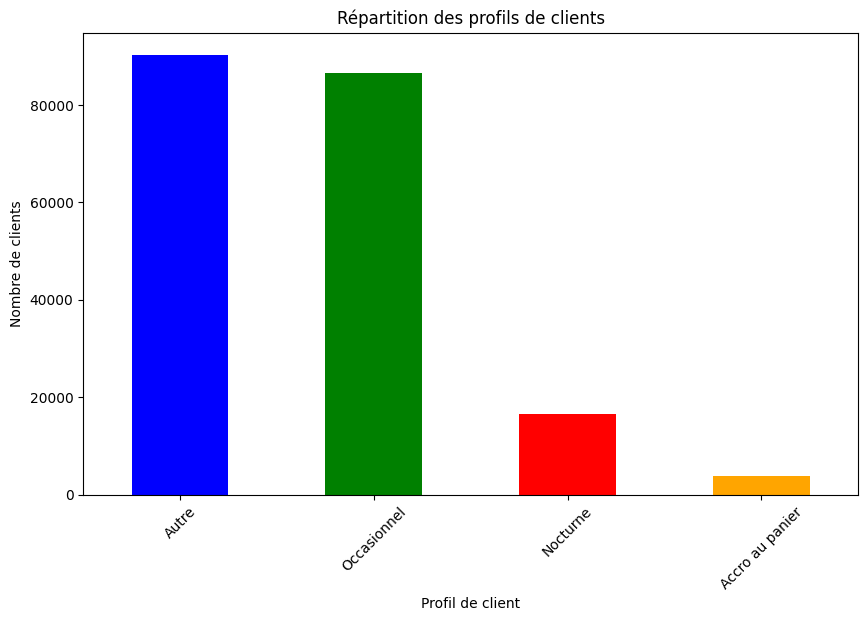

profil
Autre              90320
Occasionnel        86657
Nocturne           16609
Accro au panier     3772
Name: count, dtype: int64


In [13]:
# Définir les profils de clients
df_orders['nocturne'] = df_orders['order_hour_of_day'].between(20, 23) | df_orders['order_hour_of_day'].between(0, 6)
df_orders['occasionnel'] = df_orders['days_since_prior_order'] > 15
df_orders['accro_panier'] = df_orders['days_since_prior_order'] < 2

# Compter le nombre de clients pour chaque profil
profil_counts = df_orders.groupby('user_id').agg({
    'nocturne': 'sum',
    'occasionnel': 'sum',
    'accro_panier': 'sum'
}).reset_index()

# Définir les profils en fonction des critères
profil_counts['profil'] = profil_counts.apply(
    lambda row: 'Nocturne' if row['nocturne'] >= 3 else
    ('Occasionnel' if row['occasionnel'] >= 2 else
    ('Accro au panier' if row['accro_panier'] >= 3 else 'Autre')),
    axis=1
)

# Compter le nombre de clients pour chaque profil
profil_distribution = profil_counts['profil'].value_counts()

# Visualiser les résultats
plt.figure(figsize=(10, 6))
profil_distribution.plot(kind='bar', color=['blue', 'green', 'red', 'orange'])
plt.title('Répartition des profils de clients')
plt.xlabel('Profil de client')
plt.ylabel('Nombre de clients')
plt.xticks(rotation=45)
plt.show()

# Afficher les résultats
print(profil_distribution)

### ANTOINE : Quel article les clients ajoutent-ils en premier à leur panier ?

             product_name  first_product_count
0                  Banana                46970
1  Bag of Organic Bananas                33428
2      Organic Whole Milk                13120
3    Organic Strawberries                11673
4    Organic Hass Avocado                10212
5    Organic Baby Spinach                 9834
6         Organic Avocado                 9516
7            Spring Water                 7159
8            Strawberries                 6928
9     Organic Raspberries                 6183


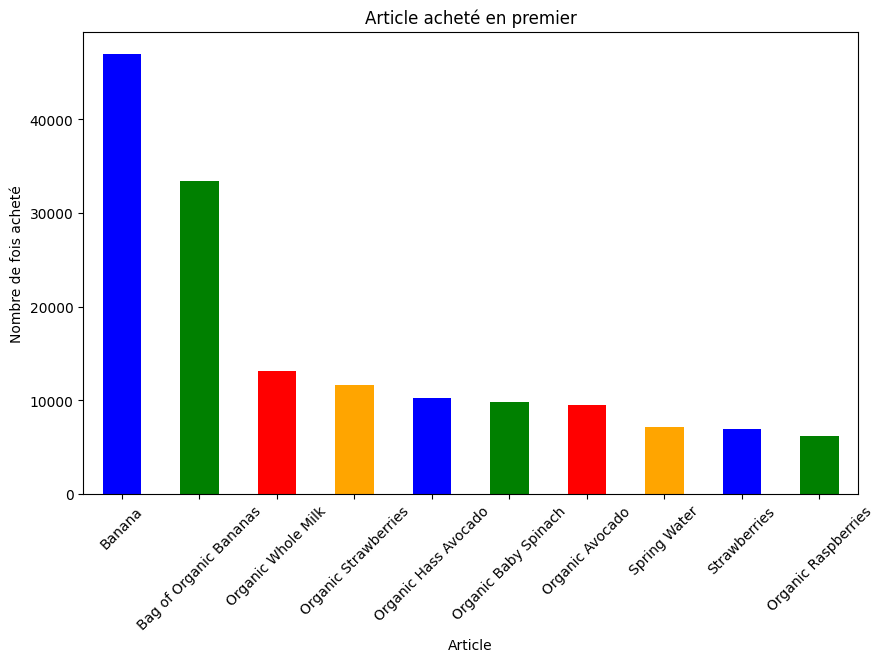

In [14]:
# Identifier le produit le plus souvent acheté en premier
df_order_products["first_product"] = df_order_products.groupby("order_id")["add_to_cart_order"].transform("min") == df_order_products["add_to_cart_order"]

# Compter le nombre de fois que chaque produit a été acheté en premier
first_product_counts = df_order_products[df_order_products["first_product"]].groupby("product_id").size().reset_index(name="first_product_count")

# Trier les produits par nombre de fois achetés en premier et prendre les 10 premiers
top_first_products = first_product_counts.sort_values(by="first_product_count", ascending=False).head(10)
# Ajouter les noms des produits
top_first_products = top_first_products.merge(df_products[["product_id", "product_name"]], on="product_id", how="left")

# Afficher les résultats
print(top_first_products[["product_name", "first_product_count"]])

# Visualiser les résultats
plt.figure(figsize=(10, 6))
top_first_products.set_index("product_name")["first_product_count"].plot(kind='bar', color=['blue', 'green', 'red', 'orange'])
plt.title('Article acheté en premier')
plt.xlabel('Article')
plt.ylabel('Nombre de fois acheté')
plt.xticks(rotation=45)
plt.show()

### ANTOINE : Quels produits ont le plus de chances d’être commandés à nouveau ?

                                         product_name  total_orders  \
0                              Purified Water, 9.5pH+           124   
1                                  Puffed Corn Cereal            71   
2                              Homestyle Orange Juice           135   
3                                Nearly Naked Popcorn            58   
4                                                 TAB            63   
5   Fragrance Free Clay with Natural Odor Eliminat...            55   
6        Superfood Cranberry, Almond & Lucuma Seedbar            67   
7                                Lo-Carb Energy Drink           221   
8                     Half And Half Ultra Pasteurized          1224   
9                      Organic Homogenized Whole Milk          1643   
10                               Wheat Sandwich Bread           416   
11                           Alimentum Infant Formula            56   
12                                   Ale, Hop Stoopid            63   
13    

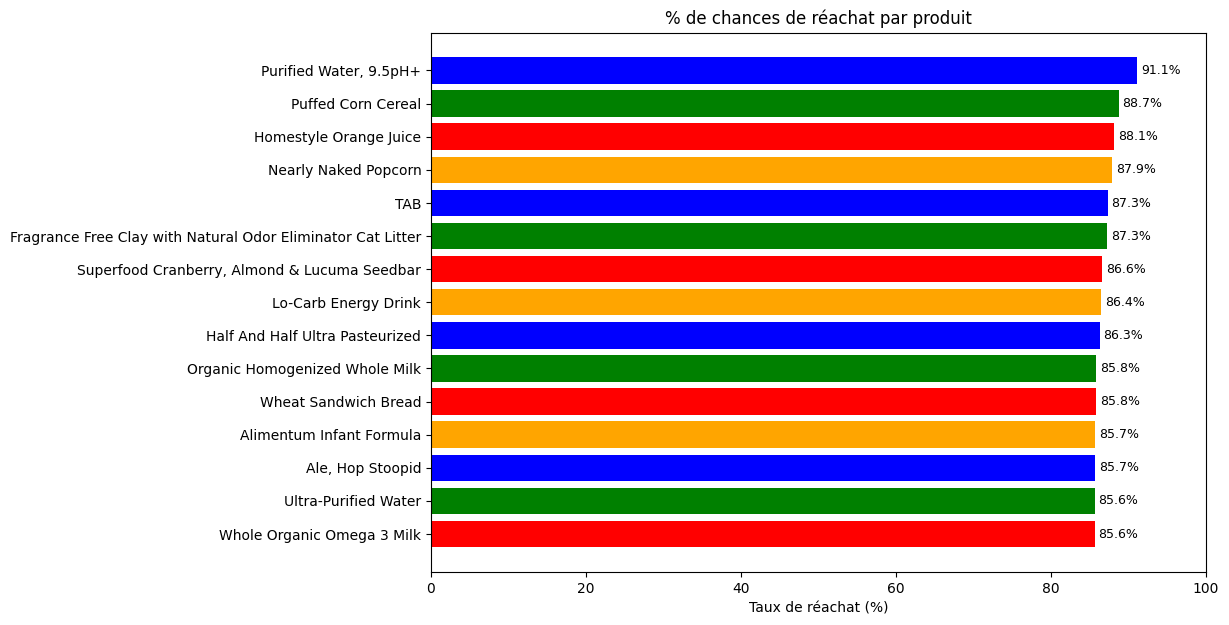

In [15]:
# Calculer le taux de réachat par produit
reorder_stats = df_order_products.groupby('product_id').agg(
    total_orders=('reordered', 'count'),
    total_reorders=('reordered', 'sum')
).reset_index()

# Calculer le taux de réachat (en %)
reorder_stats['reorder_rate'] = reorder_stats['total_reorders'] / reorder_stats['total_orders']

# Filtrer les produits avec suffisamment de commandes pour être statistiquement fiables
reorder_stats = reorder_stats[reorder_stats['total_orders'] >= 50]

# Trier par taux de réachat et prendre les 15 meilleurs
top_reordered = reorder_stats.sort_values('reorder_rate', ascending=False).head(15)

# Ajouter les noms des produits
top_reordered = top_reordered.merge(df_products[['product_id', 'product_name']], on='product_id', how='left')

# Afficher les résultats
print(top_reordered[['product_name', 'total_orders', 'total_reorders', 'reorder_rate']])

# Visualiser les résultats — graphique horizontal pour lisibilité des noms
fig, ax = plt.subplots(figsize=(10, 7))

colors = plt.cm.RdYlGn(np.linspace(0.4, 0.9, len(top_reordered)))
bars = ax.barh(
    top_reordered['product_name'],
    top_reordered['reorder_rate'] * 100,
    color=['blue', 'green', 'red', 'orange']
)

# Ajouter les valeurs sur les barres
for bar in bars:
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2,
            f'{bar.get_width():.1f}%', va='center', fontsize=9)

plt.title('% de chances de réachat par produit')
ax.set_xlabel('Taux de réachat (%)')
ax.set_xlim(0, 100)
ax.invert_yaxis()
plt.show()

# Modeles

Initialisations des données

In [16]:
# Fusion des datasets nécessaires
data = df_order_products.merge(df_orders, on="order_id")
data = data.merge(df_products, on="product_id")

data.head()

# Nombre de fois qu'un utilisateur a acheté un produit
user_product_count = data.groupby(['user_id','product_id']).size().reset_index(name="user_product_count")

# Nombre total de commandes d'un utilisateur
user_total_orders = data.groupby("user_id")["order_number"].max().reset_index(name="user_total_orders")

data = data.merge(user_product_count, on=['user_id','product_id'])
data = data.merge(user_total_orders, on="user_id")

features = [
    "order_number",
    "order_dow",
    "order_hour_of_day",
    "days_since_prior_order",
    "add_to_cart_order",
    "user_product_count",
    "user_total_orders"
]

X = data[features]
y = data["reordered"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

### Test modele 1

Ayant lu la documentation de la logisitc regression (https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), je me suis dit que pour ce projet cela pouvait bien fonctionner surtout avec les questions faites précédemment étant donné que cela sert a prédire une probabilité assez facilement

In [17]:
model_lr = LogisticRegression(max_iter=1000)

model_lr.fit(X_train, y_train)

y_pred_lr = model_lr.predict(X_test)

print(accuracy_score(y_test, y_pred_lr))

print(classification_report(y_test, y_pred_lr))

0.8017886803291996
              precision    recall  f1-score   support

         0.0       0.71      0.78      0.74    948047
         1.0       0.86      0.81      0.84   1614289

    accuracy                           0.80   2562336
   macro avg       0.79      0.80      0.79   2562336
weighted avg       0.81      0.80      0.80   2562336



La valeur renvoyée (accuracy) est le ratio de prédiction correcte effectué par le modèle (ici 80% des prédictions sont correctes), puis on analyse plus précisément avec classification_report pour mieux comprendre les prédictions

### Classe 0 - Non reorder
Precision : Ce produit ne sera pas "reorder", il a raison 71% du temps
Recall : Pour tout les produits réellement "non reorder", il a raison 78% du temps

### Classe 1  - Reorder
Precision : Ce produit sera "reorder", il a raison 86% du temps
Recall : Pour tout les produits réellement "reorder", il a raison 81% du temps

### F1-Score
C'est la moyenne entre Precision et Recall

### Support
Nombre d'exemples dans le datasets

### ---

### Macro avg
Calcul la moyenne de chaque classe sans tenir compte du nombre d'exemple

### Weighted avg
Calcul la moyen de chaque classe en tenant compte du nombre d'exemple dans le datasets

In [18]:
joblib.dump(model_lr, "model-antoine.joblib")
joblib.dump(X_train.columns.tolist(), "model_column-antoine.joblib")

['model_column-antoine.joblib']